In [21]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler


rng = np.random.default_rng()

Questão 1

In [22]:

def randomwalklento(probabilidade, passos):
    
    x = [0]
    
    for i in  range(passos):
        
        r = rng.random()
        
        if r >= 1-probabilidade:
            x.append(x[-1] + 1)
        else:
            x.append(x[-1] - 1)
            
            
    return x


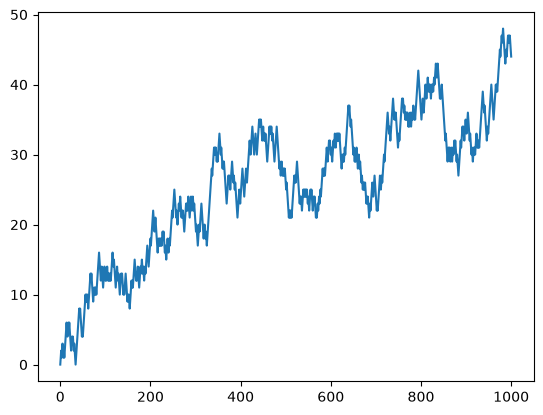

In [23]:
plt.plot(randomwalklento(0.53, 1000))
plt.show()


Questão 2

In [24]:

def randomwalkrapido(probabilidade, passos):
    
    passos = rng.choice(a =[1,-1], size= 100, replace= True, p = [probabilidade , 1-probabilidade])
    
    trajetoria = np.cumsum(passos)
    
    return trajetoria


In [25]:
traj =  randomwalkrapido(0.55 , 100)

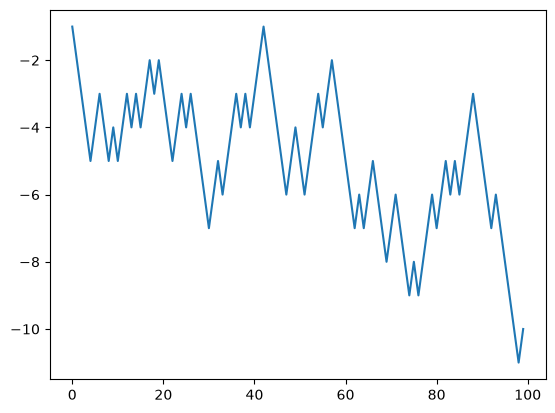

In [26]:
plt.plot(traj)
plt.show()


Questão 3

In [27]:

def randomwalkrapido(probabilidade, passos, bebados):

    traj = np.zeros(bebados)
    
    passos = rng.choice(a =[1,-1], size= [passos , bebados], replace= True, p = [probabilidade , 1-probabilidade])
    
    trajetoria = np.cumsum(passos, axis = 0)
    
    traj = np.vstack([traj, trajetoria])
    
    return traj


Questão 4

In [28]:

trajetoria1 = randomwalkrapido(0.62, 1000, 500)
trajetoria2 = randomwalkrapido(0.50, 1000 , 500)

tons_azul = ['#03045e', '#023e8a', '#0077b6', '#0096c7', '#00b4d8']
tons_rosa = ['#590d22', '#800f2f', '#a4133c', '#c9184a', '#ff4d6d']

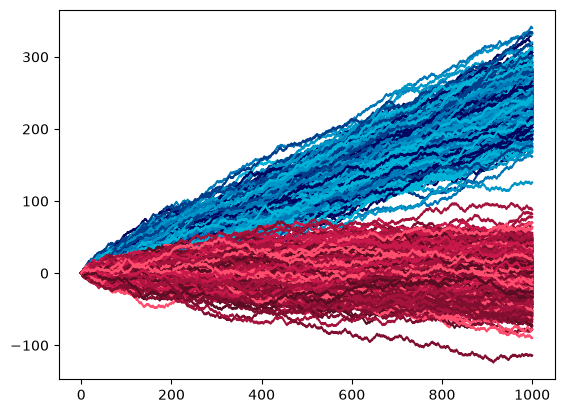

In [29]:
plt.gca().set_prop_cycle(cycler(color=tons_azul))
plt.plot(trajetoria1)
plt.gca().set_prop_cycle(cycler(color=tons_rosa))
plt.plot(trajetoria2)
plt.show()

Questão 5

In [30]:

def randomwalkrapido(probabilidade, passos, bebados):

    traj = np.zeros(bebados)
    
    passos = rng.choice(a =[1,-1], size= [passos , bebados], replace= True, p = [probabilidade , 1-probabilidade])
    
    trajetoria = np.cumsum(passos, axis = 0)
    
    traj = np.vstack([traj, trajetoria])
    
    media = np.mean(trajetoria, axis = 1,  keepdims = True)
 
    desviopadrao = np.std(trajetoria, axis = 1, dtype = 'float64', keepdims = True)
        
    return traj , media , desviopadrao


In [31]:
x1 , media1 , desviopadrao1 = randomwalkrapido(0.62, 1000, 500)
x2 , media2 , desviopadrao2 = randomwalkrapido(0.50, 1000, 500)

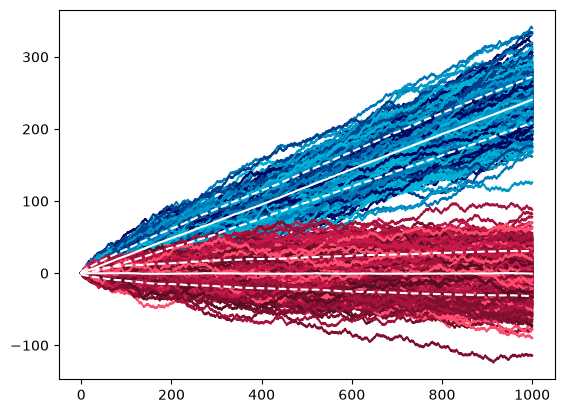

In [32]:
plt.gca().set_prop_cycle(cycler(color=tons_azul))
plt.plot(trajetoria1)
plt.gca().set_prop_cycle(cycler(color=tons_rosa))
plt.plot(trajetoria2)

plt.plot(media1, c='white')
plt.plot(media1 + desviopadrao1, c='white', ls='--')
plt.plot(media1 - desviopadrao1, c='white', ls='--')

plt.plot(media2, c='white')
plt.plot(media2 + desviopadrao2, c='white', ls='--')
plt.plot(media2 - desviopadrao2, c='white', ls='--')

plt.show()

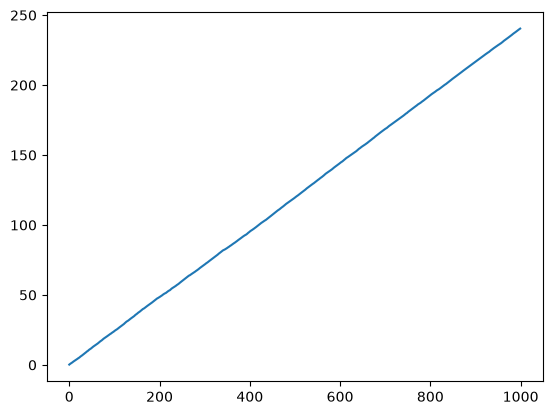

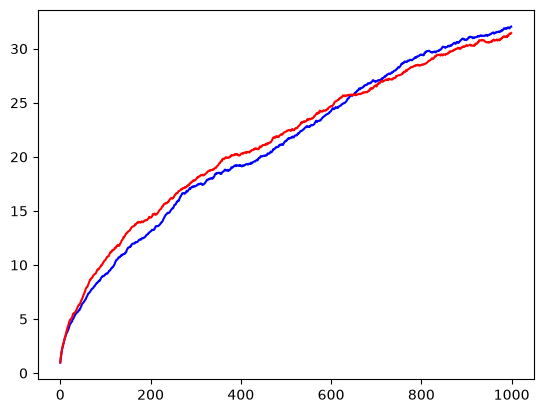

In [33]:
plt.plot(media1)
plt.show()

plt.plot(desviopadrao1, c = "blue")
plt.plot(desviopadrao2, c = "red")
plt.show()

Questão 6

In [34]:
# x1[0] # t = 0
# x1[500] # t = meio
# x1[-1] # t = final


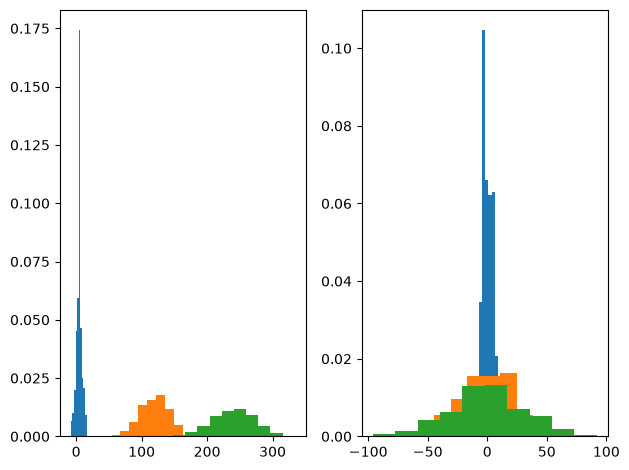

In [35]:
plt.subplot(1, 2, 1)
plt.hist(x1[20], density= True)

plt.hist(x1[500], density=True)

plt.hist(x1[-1], density= True)

plt.subplot(1,2,2)
plt.hist(x2[20], density= True)

plt.hist(x2[500], density=True)

plt.hist(x2[-1], density= True)

plt.tight_layout()
plt.show()

Questão 7

In [36]:
num_bins = 100
bin_edges1 = np.linspace(x1.min(), x1.max(), num_bins+1)
bin_edges2 = np.linspace(x2.min(), x2.max(), num_bins+1)
hist1 = np.array([np.histogram(linha, bins= bin_edges1)[0] for linha in x1])
hist2 = np.array([np.histogram(linha, bins = bin_edges2)[0] for linha in x2])

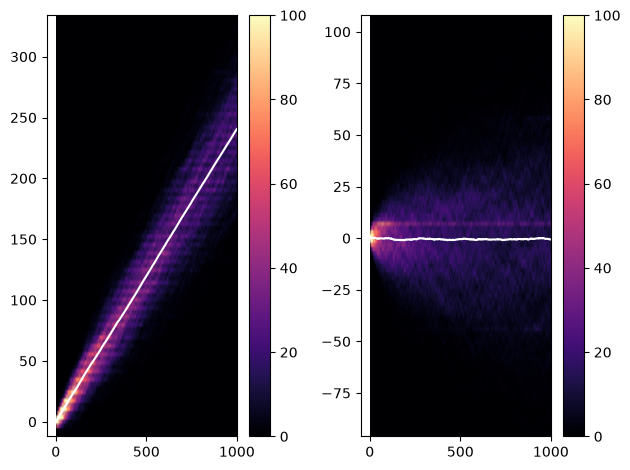

In [ ]:
plt.subplot(1,2,1)
plt.imshow(hist1.T, aspect='auto', origin='lower', extent=[1, len(x1), x1.min(), x1.max()], vmin=0, vmax=100, cmap = 'magma')
plt.colorbar()
plt.plot(media1, c='white')

plt.subplot(1,2,2)
plt.imshow(hist2.T, aspect='auto', origin='lower', extent=[1, len(x2), x2.min(), x2.max()], vmin=0, vmax=100, cmap = 'magma')
plt.colorbar()
plt.plot(media2, c='white')

plt.tight_layout()

plt.show()

In [41]:
tempo1 = np.arange(len(hist1))
posicoes1 = np.linspace(x1.min(), x1.max(), hist1.shape[1])
tempo1, posicoes1 = np.meshgrid(tempo1, posicoes1)

tempo2 = np.arange(len(hist2))
posicoes2 = np.linspace(x2.min(), x2.max(), hist2.shape[1])
tempo2 , posicoes2 = np.meshgrid(tempo2 , posicoes2)


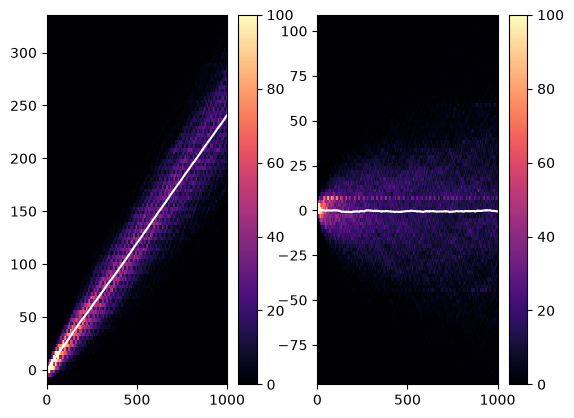

In [43]:
plt.subplot(1,2,1)
plt.plot(media1, c = 'white')
plt.pcolormesh(tempo1, posicoes1, hist1.T, shading='nearest', vmin=0, vmax=100, rasterized=True, cmap = 'magma')
plt.colorbar()
plt.subplot(1,2,2)
plt.plot(media2, c = 'white')
plt.pcolormesh(tempo2, posicoes2, hist2.T, shading='nearest', vmin=0, vmax=100, rasterized=True, cmap = 'magma')
plt.colorbar()

plt.show()